# 08 – Customer Segmentation
**Telecom Customer Intelligence & Retention Platform**

**Milestone 8: Customer Segmentation**

**Goal:** Group customers into meaningful segments based on their behavior, demographics, and usage patterns.

**Approach:**
- Use K-Means clustering on engineered features
- Determine optimal number of clusters using elbow method and silhouette analysis
- Evaluate clusters with Silhouette Score and Davies-Bouldin Index
- Analyze cluster characteristics and derive business insights
- Check cluster stability

**Input:** `customer_features.csv` (from Milestone 7)

**Output:** Cluster assignments saved to data, with interpretation of each segment

## 1. Setup and Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print('Libraries imported successfully')

Libraries imported successfully


In [2]:
# Load the customer features data
data_path = r"D:\Ahmed\My Projects\telecom intelligence project\data\processed\customer_features.csv"
df = pd.read_csv(data_path)

print(f"Data shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head())

Data shape: (10000, 38)

Columns: ['customer_id', 'age', 'gender', 'region', 'contract_type', 'monthly_charges', 'age_missing', 'tenure_months', 'signed_up_after_window_start', 'call_minutes_mean', 'call_minutes_std', 'call_minutes_min', 'call_minutes_max', 'call_minutes_slope', 'call_minutes_recent_vs_early', 'call_minutes_cv', 'data_usage_gb_mean', 'data_usage_gb_std', 'data_usage_gb_min', 'data_usage_gb_max', 'data_usage_gb_slope', 'data_usage_gb_recent_vs_early', 'data_usage_gb_cv', 'sms_count_mean', 'sms_count_std', 'sms_count_min', 'sms_count_max', 'sms_count_slope', 'sms_count_recent_vs_early', 'sms_count_cv', 'complaints_total', 'complaints_mean', 'complaint_months', 'complaints_recent3', 'active_months', 'data_gb_per_charge', 'minutes_per_charge', 'churn']

First few rows:
  customer_id   age  gender    region contract_type  monthly_charges  \
0      CUST_0   NaN    Male     Urban        Yearly            48.18   
1      CUST_1   NaN  Female  Suburban       Prepaid            

## 2. Data Preparation for Clustering

In [3]:
# Separate customer_id and target (churn) from features
customer_ids = df['customer_id'].copy()
churn_labels = df['churn'].copy()

# Features for clustering (exclude customer_id and churn)
feature_cols = [col for col in df.columns if col not in ['customer_id', 'churn']]
X = df[feature_cols].copy()

print(f"Features for clustering: {len(feature_cols)}")
print(f"\nFeature types:")
print(X.dtypes)

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"\nCategorical columns: {cat_cols}")
print(f"Numerical columns: {len(num_cols)}")

Features for clustering: 36

Feature types:
age                              float64
gender                               str
region                               str
contract_type                        str
monthly_charges                  float64
age_missing                        int64
tenure_months                      int64
signed_up_after_window_start       int64
call_minutes_mean                float64
call_minutes_std                 float64
call_minutes_min                 float64
call_minutes_max                 float64
call_minutes_slope               float64
call_minutes_recent_vs_early     float64
call_minutes_cv                  float64
data_usage_gb_mean               float64
data_usage_gb_std                float64
data_usage_gb_min                float64
data_usage_gb_max                float64
data_usage_gb_slope              float64
data_usage_gb_recent_vs_early    float64
data_usage_gb_cv                 float64
sms_count_mean                   float64
sms_count_std

In [4]:
# Handle missing values before preprocessing
print("Missing values before imputation:")
print(X.isnull().sum()[X.isnull().sum() > 0])

# Simple imputation for numerical columns (median)
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy='median')
X[num_cols] = num_imputer.fit_transform(X[num_cols])

# Categorical columns - no missing values expected but handle if any
cat_imputer = SimpleImputer(strategy='most_frequent')
if cat_cols:
    X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])

print("\nMissing values after imputation:")
print(X.isnull().sum().sum())

Missing values before imputation:
age                   3500
monthly_charges         54
data_gb_per_charge      54
minutes_per_charge      54
dtype: int64

Missing values after imputation:
0


In [5]:
# Encode categorical variables and scale numerical variables
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_processed = preprocessor.fit_transform(X)

print(f"Processed data shape: {X_processed.shape}")
print(f"\nSample of processed features (first 5 rows, first 10 columns):")
print(X_processed[:5, :10])

Processed data shape: (10000, 38)

Sample of processed features (first 5 rows, first 10 columns):
[[-0.02258902 -0.12018861  1.36277029 -0.31918466 -0.28495257 -0.05242239
   0.43006553  0.09794223  0.16790265  0.51006664]
 [-0.02258902 -0.73031524  1.36277029  0.3994107  -0.28495257 -0.41469189
   0.33835798 -0.26993456 -0.08590398 -0.37018998]
 [-0.02258902 -0.14462009  1.36277029 -0.98645178 -0.28495257  1.18795833
  -0.81666619  1.06378849  0.83250971 -0.95891233]
 [ 1.55184716 -1.33383877 -0.73379939 -0.67848234 -0.28495257  0.3084023
   0.36706202  0.08727633  0.09366978  0.10221432]
 [-0.02258902  0.76726831  1.36277029  1.4259755  -0.28495257  0.07446529
   0.25118305  0.29409794  0.26752587 -1.14548804]]


## 3. Determine Optimal Number of Clusters

K=2: Inertia=309012.10, Silhouette=0.0669
K=3: Inertia=293929.04, Silhouette=0.0616
K=4: Inertia=279851.16, Silhouette=0.0617
K=5: Inertia=269377.50, Silhouette=0.0573
K=6: Inertia=260823.25, Silhouette=0.0577
K=7: Inertia=253110.20, Silhouette=0.0609
K=8: Inertia=247556.00, Silhouette=0.0615
K=9: Inertia=242909.91, Silhouette=0.0559
K=10: Inertia=237642.80, Silhouette=0.0627


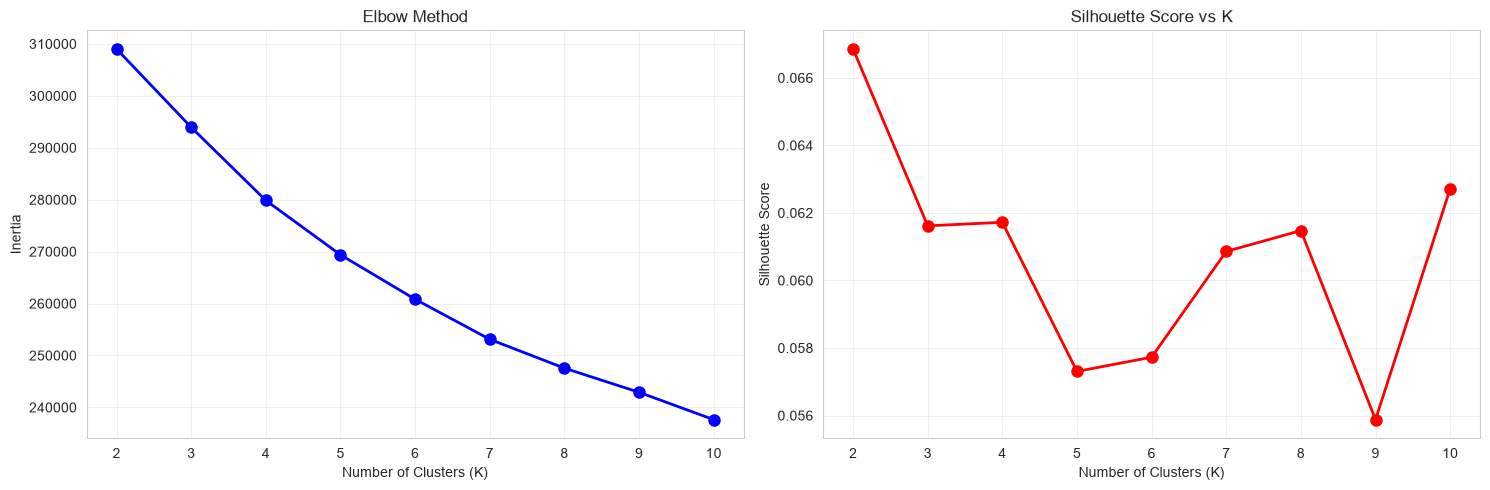


Optimal K based on elbow method and silhouette score:
Highest silhouette score at K=2 (score=0.0669)


In [6]:
# Elbow method to find optimal k
inertia_values = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_processed)
    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_processed, kmeans.labels_))
    print(f"K={k}: Inertia={kmeans.inertia_:.2f}, Silhouette={silhouette_score(X_processed, kmeans.labels_):.4f}")

# Plot elbow method
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(K_range, inertia_values, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nOptimal K based on elbow method and silhouette score:")
optimal_k_silhouette = K_range[np.argmax(silhouette_scores)]
print(f"Highest silhouette score at K={optimal_k_silhouette} (score={max(silhouette_scores):.4f})")

## 4. Apply K-Means Clustering

In [23]:
# Choose optimal K (you can adjust based on the elbow and silhouette analysis)
optimal_k = optimal_k_silhouette  # or set manually based on analysis
# optimal_k = 3  # or set manually based on analysis

print(f"Applying K-Means with K={optimal_k}")

# Fit final K-Means model
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_processed)

# Add cluster labels to original dataframe
df['cluster'] = cluster_labels

print(f"\nClustering complete!")
print(f"Cluster distribution:")
print(df['cluster'].value_counts().sort_index())
print(f"\nCluster percentages:")
print(df['cluster'].value_counts(normalize=True).sort_index().mul(100).round(2))

Applying K-Means with K=2

Clustering complete!
Cluster distribution:
cluster
0    4778
1    5222
Name: count, dtype: int64

Cluster percentages:
cluster
0    47.78
1    52.22
Name: proportion, dtype: float64


## 5. Evaluate Clusters

In [24]:
# Calculate evaluation metrics
silhouette_avg = silhouette_score(X_processed, cluster_labels)
davies_bouldin = davies_bouldin_score(X_processed, cluster_labels)

print("Cluster Evaluation Metrics:")
print("=" * 50)
print(f"Silhouette Score: {silhouette_avg:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")

print("\nInterpretation:")
print("- Silhouette Score: Range [-1, 1]. Higher is better. >0.5 is good, 0.25-0.5 is fair.")
print("- Davies-Bouldin Index: Lower is better. <0.5 is good, >1.0 is poor.")

Cluster Evaluation Metrics:
Silhouette Score: 0.0669
Davies-Bouldin Index: 3.5751

Interpretation:
- Silhouette Score: Range [-1, 1]. Higher is better. >0.5 is good, 0.25-0.5 is fair.
- Davies-Bouldin Index: Lower is better. <0.5 is good, >1.0 is poor.


## 6. Analyze Cluster Characteristics

In [25]:
# Analyze cluster characteristics
cluster_analysis = df.groupby('cluster').agg({
    'customer_id': 'count',
    'age': 'mean',
    'monthly_charges': 'mean',
    'tenure_months': 'mean',
    'call_minutes_mean': 'mean',
    'data_usage_gb_mean': 'mean',
    'sms_count_mean': 'mean',
    'complaints_total': 'mean',
    'churn': 'mean'
}).round(2)

cluster_analysis.columns = ['customers', 'avg_age', 'avg_monthly_charges', 'avg_tenure', 
                           'avg_call_minutes', 'avg_data_gb', 'avg_sms', 'avg_complaints', 'churn_rate']

print("Cluster Characteristics:")
print(cluster_analysis)

# Add categorical distributions
print("\n\nCluster distributions by categorical variables:")
for cat_col in cat_cols:
    print(f"\n{cat_col}:")
    print(pd.crosstab(df['cluster'], df[cat_col], normalize='index') * 100)

Cluster Characteristics:
         customers  avg_age  avg_monthly_charges  avg_tenure  \
cluster                                                        
0             4778    42.90                50.27       39.20   
1             5222    43.89                49.75       39.24   

         avg_call_minutes  avg_data_gb  avg_sms  avg_complaints  churn_rate  
cluster                                                                      
0                  419.70         9.99    24.46            4.14        0.08  
1                  570.89        10.01    24.60            4.89        0.08  


Cluster distributions by categorical variables:

gender:
gender      Female       Male
cluster                      
0        50.104646  49.895354
1        50.325546  49.674454

region:
region       Rural   Suburban      Urban
cluster                                 
0        33.047300  34.198409  32.754290
1        33.167369  33.856760  32.975871

contract_type:
contract_type    Monthly    Prepaid   

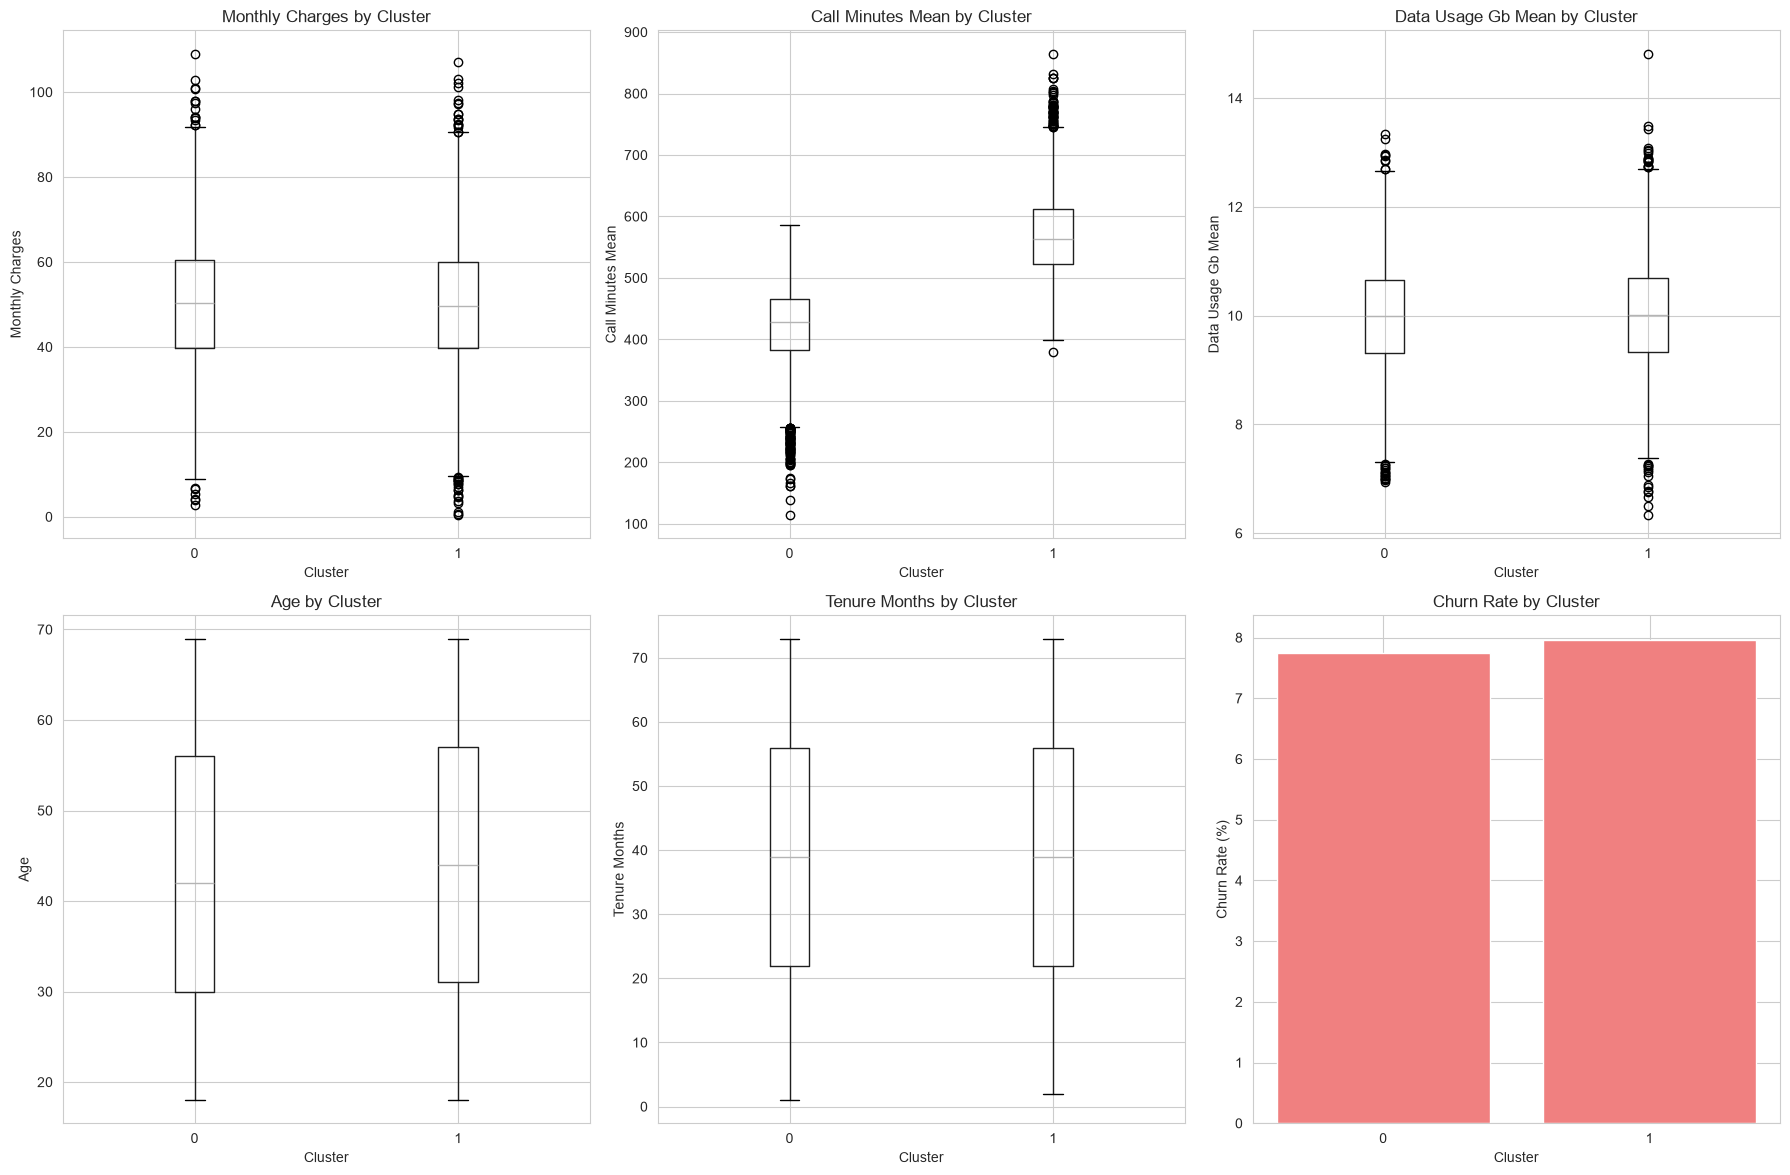

In [26]:
# Visualize cluster characteristics
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Plot 1: Monthly charges by cluster
for i, col in enumerate(['monthly_charges', 'call_minutes_mean', 'data_usage_gb_mean']):
    row = i // 3
    col_idx = i % 3
    df.boxplot(column=col, by='cluster', ax=axes[row, col_idx])
    axes[row, col_idx].set_title(f'{col.replace("_", " ").title()} by Cluster')
    axes[row, col_idx].set_xlabel('Cluster')
    axes[row, col_idx].set_ylabel(col.replace("_", " ").title())

# Plot 2: Age and tenure by cluster
for i, col in enumerate(['age', 'tenure_months']):
    row = 1 // 3
    col_idx = i % 3
    df.boxplot(column=col, by='cluster', ax=axes[1, col_idx])
    axes[1, col_idx].set_title(f'{col.replace("_", " ").title()} by Cluster')
    axes[1, col_idx].set_xlabel('Cluster')
    axes[1, col_idx].set_ylabel(col.replace("_", " ").title())

# Plot 3: Churn rate by cluster
churn_by_cluster = df.groupby('cluster')['churn'].mean() * 100
axes[1, 2].bar(churn_by_cluster.index, churn_by_cluster.values, color='lightcoral')
axes[1, 2].set_title('Churn Rate by Cluster')
axes[1, 2].set_xlabel('Cluster')
axes[1, 2].set_ylabel('Churn Rate (%)')
axes[1, 2].set_xticks(churn_by_cluster.index)

plt.suptitle('')
plt.tight_layout()
plt.show()

## 7. Business Interpretation of Clusters

In [27]:
# Create cluster profiles based on characteristics
print("Business Interpretation of Clusters:")
print("=" * 60)

print(df['cluster'].unique())

for cluster_id in sorted(df['cluster'].unique()):
    cluster_data = df[df['cluster'] == cluster_id]
    print(f"\n--- Cluster {cluster_id} ---")
    print(f"Size: {len(cluster_data)} customers ({len(cluster_data)/len(df)*100:.1f}%)")
    print(f"Churn Rate: {cluster_data['churn'].mean()*100:.2f}%")
    print(f"Avg Monthly Charges: ${cluster_data['monthly_charges'].mean():.2f}")
    print(f"Avg Tenure: {cluster_data['tenure_months'].mean():.1f} months")
    print(f"Avg Call Minutes: {cluster_data['call_minutes_mean'].mean():.1f}")
    print(f"Avg Data Usage: {cluster_data['data_usage_gb_mean'].mean():.2f} GB")
    print(f"Avg Complaints: {cluster_data['complaints_total'].mean():.2f}")
    
    # Contract type distribution
    if 'contract_type' in df.columns:
        print(f"Contract Type: {cluster_data['contract_type'].value_counts().to_dict()}")
    
    # Region distribution
    if 'region' in df.columns:
        print(f"Region: {cluster_data['region'].value_counts().to_dict()}")

Business Interpretation of Clusters:
[1 0]

--- Cluster 0 ---
Size: 4778 customers (47.8%)
Churn Rate: 7.74%
Avg Monthly Charges: $50.27
Avg Tenure: 39.2 months
Avg Call Minutes: 419.7
Avg Data Usage: 9.99 GB
Avg Complaints: 4.14
Contract Type: {'Monthly': 1907, 'Prepaid': 1894, 'Yearly': 977}
Region: {'Suburban': 1634, 'Rural': 1579, 'Urban': 1565}

--- Cluster 1 ---
Size: 5222 customers (52.2%)
Churn Rate: 7.97%
Avg Monthly Charges: $49.75
Avg Tenure: 39.2 months
Avg Call Minutes: 570.9
Avg Data Usage: 10.01 GB
Avg Complaints: 4.89
Contract Type: {'Prepaid': 2147, 'Monthly': 2046, 'Yearly': 1029}
Region: {'Suburban': 1768, 'Rural': 1732, 'Urban': 1722}


## 8. Check Cluster Stability

In [28]:
# Check cluster stability by running K-Means multiple times with different random states
print("Checking cluster stability...")
print("=" * 50)

stability_scores = []
n_runs = 5

for i in range(n_runs):
    kmeans_temp = KMeans(n_clusters=optimal_k, random_state=42+i, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_processed)
    score = silhouette_score(X_processed, labels_temp)
    stability_scores.append(score)
    print(f"Run {i+1}: Silhouette Score = {score:.4f}")

print(f"\nStability Analysis:")
print(f"Mean Silhouette: {np.mean(stability_scores):.4f}")
print(f"Std Silhouette: {np.std(stability_scores):.4f}")
print(f"\nStable clusters should have low standard deviation (<0.05) across runs.")

Checking cluster stability...
Run 1: Silhouette Score = 0.0669
Run 2: Silhouette Score = 0.0669
Run 3: Silhouette Score = 0.0669
Run 4: Silhouette Score = 0.0669
Run 5: Silhouette Score = 0.0669

Stability Analysis:
Mean Silhouette: 0.0669
Std Silhouette: 0.0000

Stable clusters should have low standard deviation (<0.05) across runs.


## 9. Save Results

In [29]:
# Save the clustered data
output_path = r"D:\Ahmed\My Projects\telecom intelligence project\data\processed\customer_features_clustered.csv"
df.to_csv(output_path, index=False)

print(f"Clustered data saved to: {output_path}")
print(f"Final shape: {df.shape}")

# Save cluster model (optional)
import joblib
model_path = r"D:\Ahmed\My Projects\telecom intelligence project\models\kmeans_clusterer.joblib"

# Create models directory if it doesn't exist
from pathlib import Path
Path(model_path).parent.mkdir(exist_ok=True)

joblib.dump(kmeans_final, model_path)
joblib.dump(preprocessor, r"D:\Ahmed\My Projects\telecom intelligence project\models\cluster_preprocessor.joblib")

# print(f"Model saved to: {model_path}")
# print(f"Preprocessor saved to: {r'D:\Ahmed\My Projects\telecom intelligence project\models\cluster_preprocessor.joblib'}")

Clustered data saved to: D:\Ahmed\My Projects\telecom intelligence project\data\processed\customer_features_clustered.csv
Final shape: (10000, 39)


['D:\\Ahmed\\My Projects\\telecom intelligence project\\models\\cluster_preprocessor.joblib']

## 10. Summary

In [31]:
print("Customer Segmentation Summary")
print("=" * 60)
print(f"\nTotal customers segmented: {len(df)}")
print(f"Number of clusters: {optimal_k}")
print(f"Silhouette Score: {silhouette_avg:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")


Customer Segmentation Summary

Total customers segmented: 10000
Number of clusters: 2
Silhouette Score: 0.0669
Davies-Bouldin Index: 3.5751
